# Big Data Bowl 2027 — Definitive Checks and Position-Group Tests

This notebook runs every check discussed for making the findings more definitive and for extending the approach to other position groups. The tests were written into the findings doc on Nov 17, 2026, before running.

| Section | Question | Uses injury data? | Strength of result |
|---|---|---|---|
| **A. Position-drill reliability** | Can each position's own Combine drills measure movement from 1–2 attempts? | No | Can be definitive |
| **B. DB placebo-onset test** | Is the DB load-then-decline pattern tied to the timing of injury, or to who the players are? | Yes | Strengthens or weakens the main DB finding |
| **C. DB turning robustness** | Does "sharper Combine turning, fewer games missed per snap" survive other models? | Yes | Robustness check |
| **D1. Receivers and soft-tissue injuries** | Does a high-speed-load spike, then a top-speed drop, come before receiver soft-tissue injuries? | Yes | Exploratory |
| **D2. Edge-rusher bend** (optional) | Do edge rushers show the DB-style cutting signature or lower speed kept before injury? | Yes | Exploratory |
| **D3. Position drills → rookie injury** | One pre-specified position-drill measure per group vs. games missed per snap | Yes | Exploratory |
| **E. Power and sample size** | How many players or seasons would make each result definitive? | Planning | — |

**Inputs** (run from `Ben_EDA/`): `../data/`, the Combine attempt cache `outputs/rookie_injury/combine_attempts.parquet` (from the rookie-injury notebook), and the game rep caches `outputs/cross_position/<family>_reps.parquet` (from the cross-position notebook). Missing caches are rebuilt from tracking, which is slow. Without `../data/`, everything runs on synthetic data (`synthetic_rookie.py`, `synthetic_cross.py`, `synthetic_db.py`, `synthetic_ol.py` in the same folder).

**Outputs:** tables in `outputs/definitive_checks/`, and Section F prints everything to send back.

## 0. Setup

In [1]:
from pathlib import Path
import glob
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")

DATA, EXT = Path("../data"), Path("external")
ATT_CACHE = Path("outputs/rookie_injury/combine_attempts.parquet")
REP_CACHE = Path("outputs/cross_position")
OUT = Path("outputs/definitive_checks")
OUT.mkdir(parents=True, exist_ok=True)
USE_SYNTHETIC = not (DATA / "games.csv").exists()
RUN_EDGE_BEND = False        # D2 reloads tracking for edge rushers (slow on real data); set True to run it
N_BOOT = 500
SEED = 0
rng = np.random.default_rng(SEED)

SEASONS = [2023, 2024, 2025]
SNAP_EVENTS = {"ball_snap", "snap_direct", "autoevent_ballsnap"}
GROUP = {"CB": "DB", "FS": "DB", "SS": "DB", "S": "DB", "DB": "DB", "WR": "Receivers", "TE": "Receivers",
         "T": "OL", "G": "OL", "C": "OL", "OT": "OL", "OG": "OL", "DE": "Edge", "OLB": "Edge",
         "DT": "Interior DL", "NT": "Interior DL"}
STANDARD_DRILLS = "FORTY|THREE_CONE|3_CONE|SHORT_SHUTTLE|SHUTTLE|BROAD|VERTICAL|BENCH"
SOFT_TISSUE = "hamstring|groin|calf|quad|thigh|adductor|abdom|oblique"
EXCLUDE_INJURY = "concussion|head|illness|personal|rest|not injury|non-football"

# shared settings, the same as the earlier notebooks
MIN_BASELINE_GAMES, BASELINE_MIN_PCT, DROP_RATIO, MIN_OUT_GAMES, LONG_ABSENCE_GAMES = 3, 0.60, 0.50, 1, 4
MIN_SPEED_FOR_DIR, HARD_CUT_DEG_S, RETENTION_SEC, FIRST_STEP_SEC, ACC_CLIP = 2.0, 150, 0.5, 0.8, 12.0
MIN_PLAYS_PER_GAME, PRE_WINDOW, MIN_BASE_GAMES_TRK, N_CONTROLS = 5, 2, 2, 4
LOAD_THR, DROP_THR = 1.10, 0.05
SPRINT_YDS = 8.0              # D1: a play reaching this speed (yd/s) counts as high-speed
IR_MIN_GAMES, MIN_GAMES = 3, 4
PLACEBO_SHIFTS = [0, 3, 5, 7]
MEAS = ["first_step", "time_1yd", "max_decel", "max_turn", "retention"]
MEAS_NAME = {"first_step": "first step", "time_1yd": "time to 1 yard", "max_decel": "braking",
             "max_turn": "turning", "retention": "speed kept"}
print("Synthetic demo mode" if USE_SYNTHETIC else f"Real data from {DATA.resolve()}")

Real data from C:\Users\bchm5\TSLR\USC-NFL-Big-Data-Bowl-2027\data


### Shared helpers
Tracking prep, rep measures, injury onsets, and matched controls: the same definitions as the DB, cross-position, and rookie notebooks, collected here so this notebook runs on its own.

In [2]:
IDS = {"game_id": "gameId", "play_id": "playId", "nfl_id": "nflId"}
GAME_KEYS = ["gameId", "playId", "nflId"]
COMBINE_KEYS = ["nfl_id", "event_id", "drill_name", "attempt"]


def cliffs_delta(a, b):
    a = np.asarray(pd.to_numeric(pd.Series(a), errors="coerce").dropna(), float)
    b = np.asarray(pd.to_numeric(pd.Series(b), errors="coerce").dropna(), float)
    return (np.sign(a[:, None] - b[None, :])).mean() if len(a) and len(b) else np.nan


def mwu(a, b, alternative="two-sided"):
    a = pd.to_numeric(pd.Series(a), errors="coerce").dropna(); b = pd.to_numeric(pd.Series(b), errors="coerce").dropna()
    return stats.mannwhitneyu(a, b, alternative=alternative).pvalue if len(a) > 1 and len(b) > 1 else np.nan


def reps_for(r, target=0.8):
    return target * (1 - r) / (r * (1 - target)) if r is not None and np.isfinite(r) and r > 0 else np.inf


def prep_tracking(trk, keys, snap_events=None):
    trk = trk.copy()
    trk["time"] = pd.to_datetime(trk.time, format="mixed")
    trk = trk.sort_values(keys + ["time"])
    if snap_events is not None and "event" in trk.columns:
        snap = trk[trk.event.isin(snap_events)].groupby(keys[:-1]).time.min().rename("snap_time")
        trk = trk.join(snap, on=keys[:-1])
        trk["has_snap"] = trk.snap_time.notna()
        trk = trk[~trk.has_snap | (trk.time >= trk.snap_time)].drop(columns="snap_time")
    trk["frameId"] = trk.groupby(keys).cumcount() + 1
    fps = float(round(1 / trk.groupby(keys).time.diff().dt.total_seconds().median()))
    return trk.reset_index(drop=True), fps


def cutting_reps(trk, fps):
    """Per rep: peak speed, accel/decel, turn rate, hard cuts, speed kept through cuts (DB-notebook definitions)."""
    trk = trk.sort_values(GAME_KEYS + ["frameId"]).copy()
    g = trk.groupby(GAME_KEYS, sort=False)
    w = max(1, int(round(RETENTION_SEC * fps)))
    trk["long_acc"] = g.s.diff() * fps
    trk["long_acc"] = trk.groupby(GAME_KEYS).long_acc.transform(
        lambda x: x.rolling(3, center=True, min_periods=1).mean()).clip(-ACC_CLIP, ACC_CLIP)
    unwrapped = g.dir.transform(lambda d: np.rad2deg(np.unwrap(np.deg2rad(d.to_numpy()))))
    trk["turn_rate"] = unwrapped.groupby([trk[k] for k in GAME_KEYS]).diff() * fps
    trk.loc[trk.s < MIN_SPEED_FOR_DIR, "turn_rate"] = np.nan
    trk["abs_turn"] = trk.groupby(GAME_KEYS).turn_rate.transform(
        lambda x: x.abs().rolling(3, center=True, min_periods=1).median())
    local_max = trk.groupby(GAME_KEYS).abs_turn.transform(lambda x: x.rolling(5, center=True, min_periods=1).max())
    trk["is_cut"] = (trk.abs_turn >= HARD_CUT_DEG_S) & (trk.abs_turn == local_max)
    s_b, s_a = g.s.shift(w), g.s.shift(-w)
    trk["retention"] = np.where(trk.is_cut & (s_b > MIN_SPEED_FOR_DIR), s_a / s_b, np.nan)
    rep = (trk.groupby(GAME_KEYS)
              .agg(max_s=("s", "max"), max_acc=("long_acc", "max"), max_decel=("long_acc", "min"),
                   max_turn=("abs_turn", "max"), retention=("retention", "mean"), n_cuts=("is_cut", "sum"))
              .reset_index())
    rep["max_decel"] = -rep.max_decel
    return rep


def game_level_cutting(rep):
    q90 = lambda x: x.quantile(0.9)
    return (rep.assign(sprint=rep.max_s >= SPRINT_YDS)
               .groupby(["nflId", "gameId"])
               .agg(top_speed=("max_s", q90), decel=("max_decel", q90), turn_rate=("max_turn", q90),
                    retention=("retention", "median"), cuts_per_play=("n_cuts", "mean"),
                    sprint_share=("sprint", "mean"), n_plays=("playId", "nunique"))
               .reset_index())


def combine_attempt_features(ct):
    ct, fps = prep_tracking(ct, COMBINE_KEYS)
    ct["start_t"] = ct.time.where(ct.s >= 0.3).groupby([ct[k] for k in COMBINE_KEYS]).transform("min")
    ct["t"] = (ct.time - ct.start_t).dt.total_seconds()
    ct = ct[ct.t >= 0].copy()
    g = ct.groupby(COMBINE_KEYS, sort=False)
    x0, y0 = g.x.transform("first"), g.y.transform("first")
    ct["disp"] = np.hypot(ct.x - x0, ct.y - y0)
    ct["long_acc"] = g.s.diff() * fps
    ct["long_acc"] = ct.groupby(COMBINE_KEYS).long_acc.transform(
        lambda v: v.rolling(3, center=True, min_periods=1).mean()).clip(-ACC_CLIP, ACC_CLIP)
    unwrapped = g.dir.transform(lambda d: np.rad2deg(np.unwrap(np.deg2rad(d.to_numpy()))))
    ct["turn"] = unwrapped.groupby([ct[k] for k in COMBINE_KEYS]).diff().abs() * fps
    ct.loc[ct.s < MIN_SPEED_FOR_DIR, "turn"] = np.nan
    w = max(1, int(round(RETENTION_SEC * fps)))
    is_cut = (ct.turn >= HARD_CUT_DEG_S) & (ct.turn == ct.groupby(COMBINE_KEYS).turn.transform(
        lambda v: v.rolling(5, center=True, min_periods=1).max()))
    s_b, s_a = g.s.shift(w), g.s.shift(-w)
    ct["retention"] = np.where(is_cut & (s_b > MIN_SPEED_FOR_DIR), s_a / s_b, np.nan)
    ct["fs"] = np.where(ct.t <= FIRST_STEP_SEC, ct.long_acc, np.nan)
    ct["t1"] = np.where(ct.disp >= 1, ct.t, np.nan)
    ct["t10"] = np.where(ct.disp >= 10, ct.t, np.nan)
    ct["t40"] = np.where(ct.disp >= 40, ct.t, np.nan)
    out = (ct.groupby(COMBINE_KEYS)
             .agg(first_step=("fs", "max"), time_1yd=("t1", "min"), max_decel=("long_acc", "min"),
                  max_turn=("turn", "max"), retention=("retention", "mean"), time_10yd=("t10", "min"),
                  time_40yd=("t40", "min"))
             .reset_index())
    out["max_decel"] = -out.max_decel
    return out

### Load data

In [3]:
def load_nflverse(seasons):
    import nflreadpy as nfl
    return dict(snaps=nfl.load_snap_counts(seasons).to_pandas(),
                injuries=nfl.load_injuries(seasons).to_pandas(),
                id_map=nfl.load_players().to_pandas()[["gsis_id", "nfl_id", "pfr_id", "display_name", "position"]],
                schedule=nfl.load_schedules(seasons).to_pandas())


def tidy(raw, nv):
    T = {}
    games = raw["games"].rename(columns=IDS)
    T["games"] = games[games.season_type.astype(str).str.upper().str.startswith("REG")]
    T["players"] = raw["players"].rename(columns=IDS | {"nfl_position": "position", "display_name": "displayName"})
    T["snaps"], T["injuries"], T["schedule"] = nv["snaps"], nv["injuries"], nv["schedule"]
    idm = nv["id_map"].dropna(subset=["nfl_id"]).copy()
    idm["nflId"] = pd.to_numeric(idm.nfl_id, errors="coerce")
    T["id_map"] = idm.dropna(subset=["nflId"]).drop_duplicates("nflId")
    T["seasons"] = sorted(T["games"].season.unique().tolist())
    return T


def read_tracking(ids, chunksize=5_000_000):
    cols = ["game_id", "play_id", "nfl_id", "time", "x", "y", "s", "a", "dir", "event"]
    parts = []
    for f in sorted(glob.glob(str(DATA / "game_tracking_*.csv"))):
        for chunk in pd.read_csv(f, usecols=cols, chunksize=chunksize):
            parts.append(chunk[chunk.nfl_id.isin(ids)])
    return pd.concat(parts, ignore_index=True)


if USE_SYNTHETIC:
    from synthetic_rookie import make_all as make_rookie
    from synthetic_cross import make_family
    R = make_rookie()
    ROOKIE = dict(players=R["players"], combine_res=R["combine_results"], combine_trk=R["combine_tracking"],
                  id_map=R["ext_players"], injuries=R["injuries"], snaps=R["snaps"], schedule=R["schedule"])
    GAME = {k: make_family(k) for k in ["db", "receivers"] + (["front7"] if RUN_EDGE_BEND else [])}
else:
    raw = {k: pd.read_csv(DATA / f"{k}.csv") for k in ["games", "players", "combine_results"]}
    NV = load_nflverse(SEASONS)
    SHARED = tidy(raw, NV)
    ROOKIE = dict(players=raw["players"], combine_res=raw["combine_results"],
                  combine_trk=pd.read_csv(DATA / "combine_tracking.csv"),
                  id_map=NV["id_map"], injuries=NV["injuries"], snaps=NV["snaps"], schedule=NV["schedule"])
print("loaded")

loaded


## A. Position-drill reliability (no injury data)

For every position group and every drill that group runs, attempt 1 vs. attempt 2 (rank correlation), with bootstrap 95% intervals and the reps needed for a reliability of 0.8 (Spearman-Brown). Pairs need 20+ players. The sprint benchmark (40-yard and 10-yard times from tracking) is computed the same way, by group.

**What would make this definitive:** most position-drill measures well below the sprint benchmark, with intervals that exclude "1–2 attempts is enough" (an r of about 0.67 or more), in every group.

In [4]:
if ATT_CACHE.exists() and not USE_SYNTHETIC:
    att = pd.read_parquet(ATT_CACHE)
    need_sprint = not {"time_10yd", "time_40yd"} <= set(att.columns)
else:
    att, need_sprint = None, False
if att is None or need_sprint:
    ct = ROOKIE["combine_trk"].dropna(subset=["nfl_id"]).copy()
    ct["drill_name"] = ct.drill_name.astype(str).str.upper().str.replace("-", "_", regex=False)
    fresh = combine_attempt_features(ct)
    att = fresh if att is None else att.merge(fresh[COMBINE_KEYS + ["time_10yd", "time_40yd"]], on=COMBINE_KEYS, how="left")
att["drill_name"] = att.drill_name.astype(str).str.upper().str.replace("-", "_", regex=False)
pl = ROOKIE["players"].copy()
pl["group"] = pl.nfl_position.map(GROUP).fillna("Other")
att = att.merge(pl[["nfl_id", "group"]], on="nfl_id", how="left")
att["standard_drill"] = att.drill_name.str.contains(STANDARD_DRILLS)
print(att.groupby("group").nfl_id.nunique().rename("players with Combine tracking").to_string())


def pair_table(df, measure):
    w = df.pivot_table(index="nfl_id", columns="attempt", values=measure).dropna()
    return w[[1, 2]] if {1, 2} <= set(w.columns) else pd.DataFrame(columns=[1, 2])


def rel_with_ci(w, n_boot=N_BOOT):
    r = w[1].corr(w[2], method="spearman")
    boots = [w.iloc[i][1].corr(w.iloc[i][2], method="spearman")
             for i in (rng.integers(0, len(w), len(w)) for _ in range(n_boot))]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return r, lo, hi


rows = []
two = att[att.attempt.isin([1, 2])]
for (grp, drill), g in two.groupby(["group", "drill_name"]):
    if grp == "Other":
        continue
    for m in MEAS:
        w = pair_table(g, m)
        if len(w) >= 20:
            r, lo, hi = rel_with_ci(w)
            rows.append(dict(group=grp, drill=drill, position_drill=not bool(g.standard_drill.iloc[0]),
                             measure=MEAS_NAME[m], pairs=len(w), r=r, r_lo=lo, r_hi=hi,
                             reps_for_0_8=reps_for(r), reps_best_case=reps_for(hi)))
A1 = pd.DataFrame(rows).sort_values(["group", "drill", "measure"]).reset_index(drop=True)

# sprint benchmark by group: 40-yard and 10-yard times, attempt 1 vs 2 in the 40-yard dash
bench = []
forty = two[two.drill_name.str.contains("FORTY")]
for grp, g in forty.groupby("group"):
    if grp == "Other":
        continue
    for m, name in [("time_40yd", "40-yard time"), ("time_10yd", "10-yard split")]:
        if m in g.columns:
            w = pair_table(g, m)
            if len(w) >= 15:
                r, lo, hi = rel_with_ci(w)
                bench.append(dict(group=grp, measure=name, pairs=len(w), r=r, r_lo=lo, r_hi=hi, reps_for_0_8=reps_for(r)))
A_BENCH = pd.DataFrame(bench)
A1.to_csv(OUT / "A1_position_drill_reliability.csv", index=False)
A_BENCH.to_csv(OUT / "A_sprint_benchmark_by_group.csv", index=False)
print(f"{len(A1)} drill-measure pairs with 20+ players")
display(A1.round(2))
display(A_BENCH.round(2))

group
DB             118
Edge            66
Interior DL     52
OL             121
Other            5
Receivers      148
48 drill-measure pairs with 20+ players


,group,drill,position_drill,measure,pairs,r,r_lo,r_hi,reps_for_0_8,reps_best_case
0,DB,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,True,braking,71,0.69,0.53,0.78,1.80,1.12
1,DB,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,True,first step,71,0.22,-0.00,0.43,13.84,5.38
2,DB,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,True,time to 1 yard,71,0.11,-0.11,0.34,31.99,7.70
3,DB,BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION,True,turning,71,0.63,0.45,0.77,2.34,1.20
4,DB,FORTY_YARD_DASH,False,braking,66,0.53,0.32,0.72,3.59,1.59
5,DB,FORTY_YARD_DASH,False,first step,66,0.40,0.15,0.60,6.08,2.70
6,DB,FORTY_YARD_DASH,False,time to 1 yard,66,0.22,-0.03,0.46,14.01,4.62
7,DB,FORTY_YARD_DASH,False,turning,66,0.26,0.02,0.47,11.30,4.46
8,DB,LINE_DRILL,True,braking,75,0.07,-0.18,0.31,57.42,8.81
9,DB,LINE_DRILL,True,first step,75,0.25,0.03,0.44,11.88,5.15


,group,measure,pairs,r,r_lo,r_hi,reps_for_0_8
0,DB,40-yard time,39,0.69,0.43,0.88,1.80
1,DB,10-yard split,66,0.42,0.19,0.62,5.63
2,Edge,40-yard time,20,0.65,0.31,0.89,2.11
3,Edge,10-yard split,36,0.61,0.33,0.83,2.54
4,Interior DL,40-yard time,15,0.89,0.65,0.97,0.52
5,Interior DL,10-yard split,27,0.66,0.44,0.79,2.06
6,OL,40-yard time,52,0.76,0.59,0.87,1.25
7,OL,10-yard split,78,0.58,0.41,0.73,2.90
8,Receivers,40-yard time,74,0.42,0.21,0.63,5.53
9,Receivers,10-yard split,92,0.26,0.04,0.47,11.27


,group,drill_measures,median_r,max_r,median_reps,share_needing_5plus_reps,share_ci_excludes_enough,drills
0,DB,4,0.33,0.53,8.69,0.75,0.75,standard drills
1,DB,8,0.24,0.69,12.75,0.75,0.75,position drills
2,Edge,4,0.39,0.57,6.28,0.75,0.50,standard drills
3,Edge,8,0.26,0.56,11.58,0.88,0.88,position drills
4,Interior DL,4,0.48,0.78,4.30,0.25,0.25,standard drills
5,Interior DL,4,0.41,0.53,5.84,0.75,0.25,position drills
6,OL,4,0.44,0.55,5.11,0.50,0.75,standard drills
7,OL,4,0.04,0.14,64.57,1.00,1.00,position drills
8,Receivers,4,0.33,0.49,8.81,0.75,1.00,standard drills
9,Receivers,4,0.34,0.66,32.09,0.50,0.50,position drills


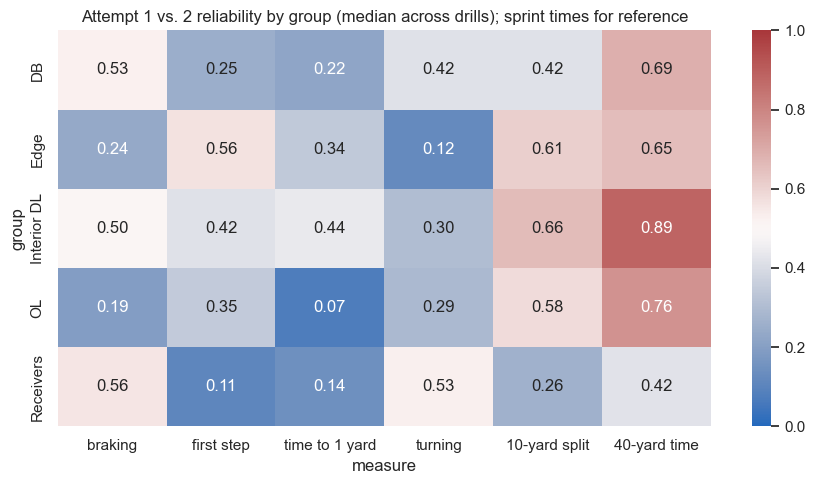

In [5]:
# A2. Summary by group: movement measures in each group's position drills vs. the sprint benchmark
if len(A1):
    A2 = (A1.groupby(["group", "position_drill"])
            .agg(drill_measures=("r", "size"), median_r=("r", "median"), max_r=("r", "max"),
                 median_reps=("reps_for_0_8", lambda x: np.median(np.clip(x, 0, 100))),
                 share_needing_5plus_reps=("reps_for_0_8", lambda x: (x >= 5).mean()),
                 share_ci_excludes_enough=("r_hi", lambda x: (x < 0.67).mean()))
            .reset_index())
    A2["drills"] = np.where(A2.position_drill, "position drills", "standard drills")
    A2 = A2.drop(columns="position_drill")
    A2.to_csv(OUT / "A2_reliability_summary_by_group.csv", index=False)
    display(A2.round(2))

    piv = A1.groupby(["group", "measure"]).r.median().unstack("measure")
    if len(A_BENCH):
        piv = piv.join(A_BENCH.pivot(index="group", columns="measure", values="r"))
    plt.figure(figsize=(9, 0.6 * len(piv) + 2))
    sns.heatmap(piv, annot=True, fmt=".2f", cmap="vlag", center=0.5, vmin=0, vmax=1)
    plt.title("Attempt 1 vs. 2 reliability by group (median across drills); sprint times for reference")
    plt.tight_layout(); plt.savefig(OUT / "A2_reliability_heatmap.png", dpi=160); plt.show()

### A3. Left/right agreement
The one drill run to both sides is the post-corner route (and any other `_LEFT`/`_RIGHT` pair found). For players who ran both, do the two sides agree, and how large is the side-to-side difference? A large, unreliable difference means a single run to one side can't characterize a player.

In [6]:
first_att = att[att.attempt == att.groupby(["nfl_id", "drill_name"]).attempt.transform("min")].copy()
first_att["base"] = first_att.drill_name.str.replace(r"_(LEFT|RIGHT)$", "", regex=True)
first_att["side"] = first_att.drill_name.str.extract(r"_(LEFT|RIGHT)$")[0]
sided = first_att.dropna(subset=["side"])
lr_rows = []
for base, g in sided.groupby("base"):
    if g.side.nunique() < 2:
        continue
    for m in MEAS:
        w = g.pivot_table(index="nfl_id", columns="side", values=m).dropna()
        if {"LEFT", "RIGHT"} <= set(w.columns) and len(w) >= 10:
            asym = (w.LEFT - w.RIGHT).abs() / ((w.LEFT.abs() + w.RIGHT.abs()) / 2)
            lr_rows.append(dict(drill=base, measure=MEAS_NAME[m], players=len(w),
                                left_vs_right_r=w.LEFT.corr(w.RIGHT, method="spearman"),
                                median_asymmetry_pct=100 * asym.median()))
A3 = pd.DataFrame(lr_rows)
A3.to_csv(OUT / "A3_left_right.csv", index=False)
display(A3.round(2) if len(A3) else "No drill has both a LEFT and a RIGHT version with 10+ players.")

,drill,measure,players,left_vs_right_r,median_asymmetry_pct
0,POST_CORNER_ROUTE,first step,65,0.25,5.01
1,POST_CORNER_ROUTE,time to 1 yard,65,-0.06,15.38
2,POST_CORNER_ROUTE,braking,65,-0.09,54.80
3,POST_CORNER_ROUTE,turning,65,-0.35,33.87


## Game-tracking helpers for Sections B, D1, D2
Injury onset from snaps (change point, confirmed on the injury report, concussions excluded), matched controls (same subgroup, similar snap share, same weeks), and game-level measures from the cached reps.

In [7]:
FAMILY_SPEC = {
    "db": dict(positions={"CB", "SS", "FS", "S", "DB"}, snap_col="defense_pct", min_pct=0.60,
               subgroup=lambda p: "CB" if p == "CB" else "S"),
    "receivers": dict(positions={"WR", "TE"}, snap_col="offense_pct", min_pct=0.60,
                      subgroup=lambda p: "TE" if p == "TE" else "WR"),
    "front7": dict(positions={"DE", "OLB"}, snap_col="defense_pct", min_pct=0.40, subgroup=lambda p: "EDGE"),
}


def build_snap_grid(snaps, schedule, pct_col):
    s = snaps[snaps.game_type == "REG"].copy()
    sch = schedule[schedule.game_type == "REG"]
    team_games = pd.concat([sch[["week", "home_team"]].rename(columns={"home_team": "team"}),
                            sch[["week", "away_team"]].rename(columns={"away_team": "team"})])
    weeks = np.sort(sch.week.unique())
    grid = (pd.MultiIndex.from_product([s.pfr_player_id.unique(), weeks], names=["pfr_player_id", "week"])
              .to_frame(index=False)
              .merge(s[["pfr_player_id", "week", "team", pct_col]], how="left", on=["pfr_player_id", "week"]))
    grid = grid.sort_values(["pfr_player_id", "week"])
    grid["team"] = grid.groupby("pfr_player_id").team.transform(lambda x: x.ffill().bfill())
    grid = grid.merge(team_games, on=["week", "team"])
    grid["pct"] = grid[pct_col].fillna(0.0)
    return grid.sort_values(["pfr_player_id", "week"]).reset_index(drop=True)


def find_onset(pct, weeks, base_min):
    import ruptures as rpt
    if len(pct) < MIN_BASELINE_GAMES + 1:
        return None
    try:
        bkps = rpt.Pelt(model="l2", min_size=1, jump=1).fit(pct.reshape(-1, 1)).predict(pen=0.15)
    except Exception:
        bkps = [len(pct)]
    for i in sorted(set(b for b in bkps[:-1]) | set(b - 1 for b in bkps[:-1])):
        if i < MIN_BASELINE_GAMES:
            continue
        base = np.median(pct[i - MIN_BASELINE_GAMES:i])
        if base < base_min:
            continue
        if pct[i] < DROP_RATIO * base and pct[i:i + 1 + MIN_OUT_GAMES].mean() < DROP_RATIO * base:
            low = pct[i:] < DROP_RATIO * base
            return int(weeks[i]), float(base), int(np.argmin(low)) if not low.all() else int(low.sum())
    return None


def family_data(key):
    """Tables, family ids, confirmed injuries, all onsets, snap grid and game-level measures for one family."""
    spec = FAMILY_SPEC[key]
    if USE_SYNTHETIC:
        rawf = GAME[key]
        T = tidy(rawf, rawf)
    else:
        rawf, T = None, SHARED
    fam_ids = set(T["players"].loc[T["players"].position.isin(spec["positions"]), "nflId"])
    pfr = set(T["id_map"].loc[T["id_map"].nflId.isin(fam_ids), "pfr_id"].dropna())
    snaps = T["snaps"][T["snaps"].pfr_player_id.isin(pfr)]
    grid = pd.concat([build_snap_grid(snaps[snaps.season == yr], T["schedule"][T["schedule"].season == yr],
                                      spec["snap_col"]).assign(season=yr) for yr in T["seasons"]], ignore_index=True)
    on = []
    for (yr, pid), g in grid.groupby(["season", "pfr_player_id"]):
        r = find_onset(g.pct.to_numpy(), g.week.to_numpy(), spec["min_pct"])
        if r:
            on.append(dict(season=yr, pfr_player_id=pid, onset_week=r[0], baseline_pct=r[1], games_low=r[2]))
    onsets = pd.DataFrame(on, columns=["season", "pfr_player_id", "onset_week", "baseline_pct", "games_low"])
    onsets = onsets.merge(T["id_map"][["pfr_id", "gsis_id", "nflId"]], left_on="pfr_player_id", right_on="pfr_id", how="left")
    rep = T["injuries"][T["injuries"].report_status.isin(["Out", "Doubtful", "Questionable"])]
    def match(row):
        m = rep[(rep.gsis_id == row.gsis_id) & (rep.season == row.season) & rep.week.between(row.onset_week, row.onset_week + 1)]
        return m.report_primary_injury.iloc[0] if len(m) else None
    onsets["reported_injury"] = onsets.apply(match, axis=1) if len(onsets) else []
    txt = onsets.reported_injury.astype(str).str.lower()
    onsets["confirmed"] = onsets.reported_injury.notna() & ~txt.str.contains("concussion|head")
    onsets["soft_tissue"] = onsets.confirmed & txt.str.contains(SOFT_TISSUE)
    tracked = T["games"].groupby("season").week.agg(["min", "max"])
    inj = onsets[onsets.confirmed & onsets.nflId.isin(fam_ids)].copy()
    inj = inj[[s in tracked.index and tracked.loc[s, "min"] < w <= tracked.loc[s, "max"] + 1
               for s, w in zip(inj.season, inj.onset_week)]]
    inj["nflId"] = inj.nflId.astype(int)
    pos_of = T["players"].set_index("nflId").position
    inj["subgroup"] = inj.nflId.map(pos_of).map(spec["subgroup"])

    cache = REP_CACHE / f"{key}_reps.parquet"
    reps = None
    if not USE_SYNTHETIC and cache.exists():
        reps = pd.read_parquet(cache)
        if "max_s" not in reps.columns:          # a burst-measure cache (front seven): rebuild with cutting measures
            reps = None
    if reps is None:
        trk = (rawf["game_tracking"] if rawf is not None else read_tracking(fam_ids)).rename(columns=IDS)
        trk = trk[trk.gameId.isin(T["games"].gameId)]
        trk, fps = prep_tracking(trk, GAME_KEYS, SNAP_EVENTS)
        reps = cutting_reps(trk, fps)
    gl = game_level_cutting(reps).merge(T["games"][["gameId", "season", "week"]], on="gameId")
    gl = gl[gl.n_plays >= MIN_PLAYS_PER_GAME]
    return dict(T=T, spec=spec, fam_ids=fam_ids, onsets=onsets, inj=inj, grid=grid, gl=gl)


def match_controls(F, inj=None, seed=SEED):
    T, gl, grid, spec = F["T"], F["gl"], F["grid"], F["spec"]
    inj = F["inj"] if inj is None else inj
    base_usage = (grid.merge(T["id_map"][["pfr_id", "nflId"]], left_on="pfr_player_id", right_on="pfr_id")
                      .groupby(["season", "nflId"]).pct.median())
    pos_of = T["players"].set_index("nflId").position
    ever = {(r.season, int(r.nflId)) for r in F["onsets"].dropna(subset=["nflId"]).itertuples()}
    weeks = gl.groupby(["season", "nflId"]).week.apply(np.array).to_dict()
    r_ = np.random.default_rng(seed)
    rows = []
    for r in inj.itertuples():
        pool = [p for p in F["fam_ids"]
                if (r.season, p) not in ever and spec["subgroup"](pos_of.get(p)) == r.subgroup
                and abs(base_usage.get((r.season, p), -1) - r.baseline_pct) <= 0.15
                and (weeks.get((r.season, p), np.array([])) < r.onset_week).sum() >= MIN_BASE_GAMES_TRK + PRE_WINDOW]
        for c in r_.choice(pool, min(N_CONTROLS, len(pool)), replace=False):
            rows.append(dict(nflId=int(c), season=r.season, onset_week=r.onset_week, match_of=r.nflId))
    controls = pd.DataFrame(rows, columns=["nflId", "season", "onset_week", "match_of"])
    return pd.concat([inj[["nflId", "season", "onset_week"]].assign(group="injured", match_of=inj.nflId),
                      controls.assign(group="control")], ignore_index=True)


def signature_at(gl, nid, season, onset, load_col, resp_col):
    """Load spike at game -2 (> LOAD_THR x baseline) then response drop (> DROP_THR) into game -1."""
    g = gl[(gl.nflId == nid) & (gl.season == season) & (gl.week < onset)].sort_values("week")
    if len(g) < MIN_BASE_GAMES_TRK + PRE_WINDOW:
        return None
    base = g.iloc[:-PRE_WINDOW][[load_col, resp_col]].median()
    m2, m1 = g.iloc[-2], g.iloc[-1]
    if not (base[load_col] > 0 and base[resp_col] > 0):
        return None
    return bool(m2[load_col] / base[load_col] > LOAD_THR and (m2[resp_col] - m1[resp_col]) / base[resp_col] > DROP_THR)


def trend_at(gl, nid, season, onset, col="top_speed"):
    """Change per game in `col` (relative to own median) over the games before onset, excluding the last 2."""
    g = gl[(gl.nflId == nid) & (gl.season == season) & (gl.week < onset)].sort_values("week").iloc[:-PRE_WINDOW]
    if len(g) < MIN_GAMES:
        return None
    v = (g[col] / g[col].median()).to_numpy()
    return float(np.polyfit(np.arange(len(v)), v, 1)[0])


def placebo_table(gl, subjects, load_col, resp_col, shifts=PLACEBO_SHIFTS):
    rows = []
    for s in subjects.itertuples():
        for sh in shifts:
            sig = signature_at(gl, s.nflId, s.season, s.onset_week - sh, load_col, resp_col)
            tr = trend_at(gl, s.nflId, s.season, s.onset_week - sh)
            rows.append(dict(nflId=s.nflId, group=s.group, shift=sh, signature=sig, top_speed_trend=tr))
    return pd.DataFrame(rows)


def summarize_placebo(pt):
    out = []
    for sh, g in pt.groupby("shift"):
        a = g[(g.group == "injured") & g.signature.notna()].signature.astype(bool)
        b = g[(g.group == "control") & g.signature.notna()].signature.astype(bool)
        ta = g[(g.group == "injured")].top_speed_trend.dropna(); tb = g[(g.group == "control")].top_speed_trend.dropna()
        orr, p = (stats.fisher_exact([[a.sum(), (~a).sum()], [b.sum(), (~b).sum()]]) if len(a) and len(b)
                  else (np.nan, np.nan))
        out.append(dict(weeks_before_real_onset=sh, injured_n=len(a), injured_rate=a.mean() if len(a) else np.nan,
                        control_n=len(b), control_rate=b.mean() if len(b) else np.nan, odds_ratio=orr, fisher_p=p,
                        speed_trend_delta=cliffs_delta(ta, tb), speed_trend_n=f"{len(ta)} vs {len(tb)}"))
    return pd.DataFrame(out)

## B. DB placebo-onset test

The DB signature (cuts per play above 1.10× baseline at game −2, then a turn-rate drop above 5% into game −1) and the top-speed trend, at the real onset (shift 0) and at fake onsets 3, 5, and 7 weeks earlier. Same players, same thresholds.

**How to read it:**
- **Injured high only at shift 0, near the control rate at fake onsets:** the pattern is tied to the timing of injury. That strongly supports the DB finding.
- **Injured high at every shift:** these players show the pattern all season; it may mark injury-prone players (a trait), not an imminent injury.
- **Injured near controls even at shift 0:** the original result doesn't reproduce with these definitions.

A pooled comparison (real onset vs. all fake onsets, injured DBs only) is the single headline number. Fake onsets further back have fewer players with enough earlier games.

DB injuries in tracking window: 29 | player-games: 1,544
group
control    60
injured    29


,weeks_before_real_onset,injured_n,injured_rate,control_n,control_rate,odds_ratio,fisher_p,speed_trend_delta,speed_trend_n
0,0,28,0.429,60,0.200,3.000,0.039,-0.267,21 vs 50
1,3,19,0.316,50,0.240,1.462,0.550,-0.237,18 vs 46
2,5,18,0.222,46,0.109,2.343,0.255,-0.351,12 vs 37
3,7,15,0.200,40,0.325,0.519,0.510,-0.337,8 vs 26


,comparison,real_rate,real_n,fake_rate,fake_n,odds_ratio,fisher_p
0,injured DBs: real onset vs. fake onsets (pooled),0.429,28,0.25,52,2.25,0.131


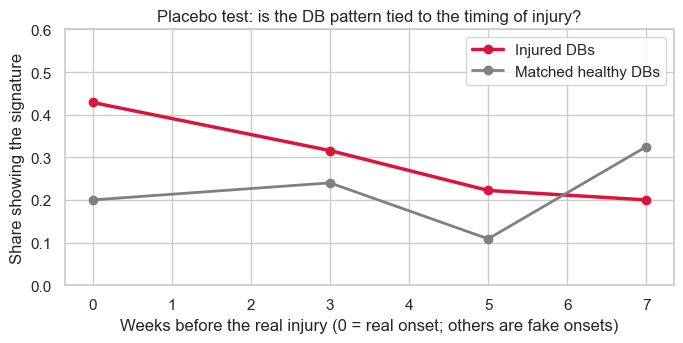

In [8]:
DB = family_data("db")
print(f"DB injuries in tracking window: {len(DB['inj'])} | player-games: {len(DB['gl']):,}")
DB_SUBJ = match_controls(DB)
print(DB_SUBJ.group.value_counts().to_string())
B_PT = placebo_table(DB["gl"], DB_SUBJ, "cuts_per_play", "turn_rate")
B1 = summarize_placebo(B_PT)
display(B1.round(3))

inj_only = B_PT[(B_PT.group == "injured") & B_PT.signature.notna()]
real = inj_only[inj_only["shift"] == 0].signature.astype(bool)
fake = inj_only[inj_only["shift"] > 0].signature.astype(bool)
orr, p = stats.fisher_exact([[real.sum(), (~real).sum()], [fake.sum(), (~fake).sum()]]) if len(real) and len(fake) else (np.nan, np.nan)
B_HEAD = pd.DataFrame([dict(comparison="injured DBs: real onset vs. fake onsets (pooled)", real_rate=real.mean(),
                            real_n=len(real), fake_rate=fake.mean(), fake_n=len(fake), odds_ratio=orr, fisher_p=p)])
display(B_HEAD.round(3))
B1.to_csv(OUT / "B1_db_placebo.csv", index=False)
B_HEAD.to_csv(OUT / "B1_db_placebo_headline.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(B1.weeks_before_real_onset, B1.injured_rate, marker="o", color="crimson", lw=2.5, label="Injured DBs")
ax.plot(B1.weeks_before_real_onset, B1.control_rate, marker="o", color="grey", lw=2, label="Matched healthy DBs")
ax.set_xlabel("Weeks before the real injury (0 = real onset; others are fake onsets)")
ax.set_ylabel("Share showing the signature"); ax.set_ylim(0, max(0.6, B1[["injured_rate", "control_rate"]].max().max() + 0.05))
ax.set_title("Placebo test: is the DB pattern tied to the timing of injury?"); ax.legend()
plt.tight_layout(); plt.savefig(OUT / "B1_db_placebo.png", dpi=160); plt.show()

## Rookie-injury helpers for Sections C and D3
Rookie games missed (weeks listed Out, plus 3+ game absences right after an injury listing), snaps played, and Combine movement traits: each measure z-scored within drill, then averaged over a player's drills (first attempts), then z-scored within position group.

In [9]:
def rookie_outcome(players, injuries, snaps, schedule, idmap):
    inj = injuries[injuries.game_type == "REG"].merge(idmap[["gsis_id", "nfl_id"]], on="gsis_id")
    inj = inj.merge(players[["nfl_id", "draft_year"]], on="nfl_id")
    inj = inj[(inj.season == inj.draft_year) & inj.report_primary_injury.notna()
              & ~inj.report_primary_injury.astype(str).str.lower().str.contains(EXCLUDE_INJURY)]
    out_weeks = inj[inj.report_status == "Out"].groupby("nfl_id").week.apply(set).to_dict()
    listed = inj.groupby("nfl_id").week.apply(set).to_dict()
    soft = inj[inj.report_primary_injury.astype(str).str.lower().str.contains(SOFT_TISSUE)].nfl_id.unique()
    sn = snaps[snaps.game_type == "REG"].merge(idmap[["pfr_id", "nfl_id"]], left_on="pfr_player_id", right_on="pfr_id")
    sn = sn.merge(players[["nfl_id", "draft_year"]], on="nfl_id")
    sn = sn[sn.season == sn.draft_year]
    sch = schedule[schedule.game_type == "REG"]
    team_weeks = (pd.concat([sch[["season", "week", "home_team"]].rename(columns={"home_team": "team"}),
                             sch[["season", "week", "away_team"]].rename(columns={"away_team": "team"})])
                    .groupby(["season", "team"]).week.apply(lambda w: sorted(set(w))).to_dict())
    by_player = {k: g for k, g in sn.groupby("nfl_id")}
    rows = []
    for nid in players.nfl_id:
        weeks, ir = set(out_weeks.get(nid, set())), set()
        g = by_player.get(nid)
        if g is not None and nid in listed:
            played, run = set(g.week), []
            for w in team_weeks.get((g.season.iloc[0], g.team.mode().iloc[0]), []) + [None]:
                if w is not None and w not in played and w > min(played):
                    run.append(w); continue
                if len(run) >= IR_MIN_GAMES and any(run[0] - 2 <= lw <= run[0] for lw in listed[nid]):
                    ir |= set(run)
                run = []
        rows.append(dict(nfl_id=nid, games_out=len(weeks | ir), games_played=0 if g is None else len(g),
                         snaps=0 if g is None else int((g.offense_snaps + g.defense_snaps).sum()),
                         soft_tissue=nid in set(soft)))
    return pd.DataFrame(rows)


idm = ROOKIE["id_map"].dropna(subset=["nfl_id"]).copy()
idm["nfl_id"] = pd.to_numeric(idm.nfl_id, errors="coerce")
idm = idm.dropna(subset=["nfl_id"]); idm["nfl_id"] = idm.nfl_id.astype(int)
RK = ROOKIE["players"].copy()
RK["group"] = RK.nfl_position.map(GROUP).fillna("Other")
RK["draft_round"] = pd.to_numeric(RK.get("draft_round"), errors="coerce").fillna(8)
RK = RK.merge(rookie_outcome(RK, ROOKIE["injuries"], ROOKIE["snaps"], ROOKIE["schedule"], idm), on="nfl_id")
RK["injured"] = RK.games_out > 0
RK = RK[RK.group != "Other"]

zatt = att.copy()
zatt[MEAS] = zatt.groupby("drill_name")[MEAS].transform(lambda x: (x - x.mean()) / x.std())
zfirst = zatt[zatt.attempt == zatt.groupby(["nfl_id", "drill_name"]).attempt.transform("min")]
comp = zfirst.groupby("nfl_id")[["retention", "max_decel", "max_turn", "first_step"]].mean().rename(
    columns={"retention": "speed_kept", "max_decel": "braking", "max_turn": "turning"})
RK = RK.merge(comp.reset_index(), on="nfl_id", how="left")
TIMED = [c for c in ["combine_weight", "forty"] if c in ROOKIE["combine_res"].columns]
RK = RK.merge(ROOKIE["combine_res"].drop_duplicates("nfl_id", keep="last")[["nfl_id"] + TIMED], on="nfl_id", how="left")
TRACKED = ["speed_kept", "braking", "turning"]
ZC = TIMED + TRACKED + ["first_step"]
RK[ZC] = RK.groupby("group")[ZC].transform(lambda x: (x - x.mean()) / x.std())
print(RK.groupby("group").agg(players=("nfl_id", "size"), with_snaps=("snaps", lambda s: (s > 0).sum()),
                              injured=("injured", "sum")).to_string())


def design(d, feats):
    X = pd.get_dummies(d.group, prefix="grp", drop_first=True).astype(float) if d.group.nunique() > 1 else pd.DataFrame(index=d.index)
    X["draft_round"] = d.draft_round
    for f in feats:
        X[f] = d[f].fillna(0.0)
        X[f"{f}_missing"] = d[f].isna().astype(float)
    X = X.loc[:, X.std() > 0]
    return sm.add_constant(X)


def effect(fit, f, kind):
    if f not in fit.params:
        return dict(estimate=np.nan, ci_low=np.nan, ci_high=np.nan, p_value=np.nan)
    ci = fit.conf_int().loc[f]
    return dict(estimate=np.exp(fit.params[f]), ci_low=np.exp(ci.iloc[0]), ci_high=np.exp(ci.iloc[1]),
                p_value=fit.pvalues[f], estimate_type=kind)


def fit_variant(d, feats, target, variant):
    d = d[d.snaps > 0].copy()
    X = design(d, feats)
    if variant == "poisson_robust":
        fit = sm.GLM(d.games_out, X, family=sm.families.Poisson(), offset=np.log(d.snaps)).fit(cov_type="HC0")
        return effect(fit, target, "rate ratio per SD")
    if variant == "negative_binomial":
        fit = sm.NegativeBinomial(d.games_out, X, exposure=d.snaps).fit(disp=0, maxiter=200)
        return effect(fit, target, "rate ratio per SD")
    if variant == "games_out_capped_at_4":
        fit = sm.GLM(d.games_out.clip(upper=4), X, family=sm.families.Poisson(), offset=np.log(d.snaps)).fit(cov_type="HC0")
        return effect(fit, target, "rate ratio per SD")
    if variant == "logistic_injured":
        dd = d[d.games_played >= MIN_GAMES]
        X2 = design(dd, feats); X2["log_snaps"] = np.log(dd.snaps)
        fit = sm.Logit(dd.injured.astype(int), X2).fit(disp=0, maxiter=200)
        return effect(fit, target, "odds ratio per SD")
    raise ValueError(variant)

             players  with_snaps  injured
group                                    
DB               118          85       24
Edge              66          54        8
Interior DL       52          40        8
OL               121          84       21
Receivers        148         115       38


## C. Robustness of the DB turning result

The original estimate: DBs with sharper Combine turning missed fewer games per snap (rate ratio 0.45 per SD). Here it is re-estimated five ways, plus with each draft class left out. A result that holds up keeps its direction (below 1) in every variant, with similar size; one driven by a few long injured-reserve stints shrinks when games missed are capped.

In [10]:
VARIANTS = ["poisson_robust", "negative_binomial", "games_out_capped_at_4", "logistic_injured"]
c_rows = []
for label, d in [("All groups", RK), ("DBs only", RK[RK.group == "DB"])]:
    for v in VARIANTS:
        try:
            c_rows.append(dict(sample=label, variant=v) | fit_variant(d, TIMED + TRACKED, "turning", v))
        except Exception as e:
            c_rows.append(dict(sample=label, variant=v, note=f"failed: {type(e).__name__}"))
    for yr in sorted(d.draft_year.unique()):
        try:
            c_rows.append(dict(sample=label, variant=f"poisson_robust, without {yr} class")
                          | fit_variant(d[d.draft_year != yr], TIMED + TRACKED, "turning", "poisson_robust"))
        except Exception as e:
            c_rows.append(dict(sample=label, variant=f"without {yr} class", note=f"failed: {type(e).__name__}"))
C = pd.DataFrame(c_rows)
C.to_csv(OUT / "C_db_turning_robustness.csv", index=False)
display(C.round(3))

,sample,variant,estimate,ci_low,ci_high,p_value,estimate_type,note
0,All groups,poisson_robust,0.624,0.428,0.909,0.014,rate ratio per SD,NaN
1,All groups,negative_binomial,0.624,NaN,NaN,NaN,rate ratio per SD,NaN
2,All groups,games_out_capped_at_4,0.757,0.579,0.989,0.041,rate ratio per SD,NaN
3,All groups,logistic_injured,0.892,0.654,1.217,0.470,odds ratio per SD,NaN
4,All groups,"poisson_robust, without 2023 class",0.527,0.336,0.827,0.005,rate ratio per SD,NaN
5,All groups,"poisson_robust, without 2024 class",0.505,0.314,0.812,0.005,rate ratio per SD,NaN
6,All groups,"poisson_robust, without 2025 class",0.888,0.574,1.374,0.594,rate ratio per SD,NaN
7,DBs only,poisson_robust,0.451,0.237,0.856,0.015,rate ratio per SD,NaN
8,DBs only,negative_binomial,0.630,0.285,1.390,0.252,rate ratio per SD,NaN
9,DBs only,games_out_capped_at_4,0.705,0.413,1.201,0.198,rate ratio per SD,NaN


## D1. Receivers: high-speed load spike, then a top-speed drop, before soft-tissue injuries

Pre-specified (findings doc, Nov 17): at game −2, the share of plays reaching 8 yd/s is above 1.10× the receiver's own baseline; then top speed drops more than 5% into game −1. Compared for (a) receivers with a soft-tissue injury (hamstring, groin, calf, quad, thigh) and (b) all receiver injuries, each against matched healthy receivers, plus the placebo check for (a). Soft-tissue injuries are the injury type most tied to high-speed running in sports science. Expect small numbers: treat this as exploratory.

In [11]:
REC = family_data("receivers")
print(f"receiver injuries in tracking window: {len(REC['inj'])} (soft tissue: {int(REC['inj'].soft_tissue.sum())})")
d1_rows, D1_PLACEBO = [], None
for label, inj in [("soft-tissue injuries", REC["inj"][REC["inj"].soft_tissue]), ("all receiver injuries", REC["inj"])]:
    if len(inj) == 0:
        d1_rows.append(dict(outcome=label, note="no injuries in the tracking window")); continue
    subj = match_controls(REC, inj=inj)
    pt = placebo_table(REC["gl"], subj, "sprint_share", "top_speed")
    s = summarize_placebo(pt)
    row0 = s[s.weeks_before_real_onset == 0].iloc[0].to_dict()
    d1_rows.append(dict(outcome=label) | row0)
    if label.startswith("soft"):
        D1_PLACEBO = s
D1 = pd.DataFrame(d1_rows)
D1.to_csv(OUT / "D1_receivers.csv", index=False)
display(D1.round(3))
if D1_PLACEBO is not None:
    print("Placebo check, soft-tissue injuries:")
    display(D1_PLACEBO.round(3))
    D1_PLACEBO.to_csv(OUT / "D1_receivers_soft_tissue_placebo.csv", index=False)

receiver injuries in tracking window: 26 (soft tissue: 9)


,outcome,weeks_before_real_onset,injured_n,injured_rate,control_n,control_rate,odds_ratio,fisher_p,speed_trend_delta,speed_trend_n
0,soft-tissue injuries,0,8,0.000,26,0.115,0.000,1.000,0.240,8 vs 25
1,all receiver injuries,0,21,0.143,72,0.069,2.233,0.374,0.163,21 vs 63


Placebo check, soft-tissue injuries:


,weeks_before_real_onset,injured_n,injured_rate,control_n,control_rate,odds_ratio,fisher_p,speed_trend_delta,speed_trend_n
0,0,8,0.00,26,0.115,0.000,1.000,0.240,8 vs 25
1,3,8,0.25,25,0.120,2.444,0.574,-0.063,6 vs 21
2,5,6,0.00,21,0.190,0.000,0.545,-0.040,5 vs 20
3,7,6,0.00,21,0.095,0.000,1.000,-0.042,4 vs 12


## D2. Edge rushers: bend (optional)

Set `RUN_EDGE_BEND = True` in Section 0 to run. It rebuilds cutting measures from tracking for DEs and OLBs (the cross-position cache stores lineman-style measures), so on real data it takes a while. Injuries use a 40% snap baseline, since edge rushers rotate. Tests: the DB-style signature (cuts spike, then turn-rate drop) with its placebo check, and whether speed kept through cuts was lower in the two games before injury.

In [12]:
D2 = None
if RUN_EDGE_BEND:
    EDGE = family_data("front7")
    print(f"edge injuries in tracking window: {len(EDGE['inj'])}")
    if len(EDGE["inj"]):
        ES = match_controls(EDGE)
        D2_PLACEBO = summarize_placebo(placebo_table(EDGE["gl"], ES, "cuts_per_play", "turn_rate"))
        ret = []
        for s in ES.itertuples():
            g = EDGE["gl"][(EDGE["gl"].nflId == s.nflId) & (EDGE["gl"].season == s.season)
                           & (EDGE["gl"].week < s.onset_week)].sort_values("week")
            if len(g) >= MIN_BASE_GAMES_TRK + PRE_WINDOW:
                base = g.iloc[:-PRE_WINDOW].retention.median()
                ret.append(dict(group=s.group, retention_pre=g.tail(PRE_WINDOW).retention.mean() / base if base else np.nan))
        ret = pd.DataFrame(ret)
        a, b = ret[ret.group == "injured"].retention_pre, ret[ret.group == "control"].retention_pre
        D2 = dict(placebo=D2_PLACEBO, speed_kept_pre=dict(injured_mean=a.mean(), control_mean=b.mean(),
                                                           cliffs_delta=cliffs_delta(a, b), p_value=mwu(a, b),
                                                           n=f"{a.notna().sum()} vs {b.notna().sum()}"))
        display(D2_PLACEBO.round(3)); print(D2["speed_kept_pre"])
        D2_PLACEBO.to_csv(OUT / "D2_edge_placebo.csv", index=False)
else:
    print("D2 skipped (RUN_EDGE_BEND = False).")

D2 skipped (RUN_EDGE_BEND = False).


## D3. Position drills → rookie injury, one measure per group

Pre-specified measure per group, averaged over that group's **position drills** (drills outside the standard 40 / three-cone / shuttle / jumps, where that group is at least 30% of the participants; if none qualify, any such drill 20+ players of the group ran):

| Group | Measure | Why |
|---|---|---|
| DB | Turning | The trait the DB game pattern centers on |
| Receivers | Braking | Deceleration into route breaks |
| OL | Braking | Stopping and redirecting in pass protection |
| Edge | Turning | Bend around the corner |
| Interior DL | First step | Get-off into contact |

For each: games missed per snap (rate ratio per SD, Poisson with robust errors, adjusted for draft round), the composite's reliability (split-half across drills, or attempt 1 vs. 2 when players have a single drill), and the noise-corrected association.

In [13]:
D3_SPEC = {"DB": "max_turn", "Receivers": "max_decel", "OL": "max_decel", "Edge": "max_turn", "Interior DL": "first_step"}
share = (zfirst[~zfirst.drill_name.str.contains(STANDARD_DRILLS)].groupby(["drill_name", "group"]).nfl_id.nunique()
         .unstack(fill_value=0))
owner = share.div(share.sum(axis=1), axis=0)


def split_half(d, m, n_splits=50):
    d = d[["nfl_id", "drill_name", m]].dropna()
    d = d[d.groupby("nfl_id")[m].transform("size") >= 2]
    if d.nfl_id.nunique() < 15:
        return np.nan
    rs = []
    for s in range(n_splits):
        r_ = np.random.default_rng(s)
        d = d.assign(half=d.groupby("nfl_id")[m].transform(lambda x: r_.permutation(len(x)) % 2))
        h = d.groupby(["nfl_id", "half"])[m].mean().unstack().dropna()
        rs.append(h[0].corr(h[1], method="spearman"))
    r = float(np.mean(rs))
    return 2 * r / (1 + r) if r > 0 else np.nan


def n_needed(r):
    return int(np.ceil(((1.96 + 0.84) / np.arctanh(abs(r))) ** 2 + 3)) if np.isfinite(r) and abs(r) >= 0.03 else np.nan


d3_rows = []
for grp, m in D3_SPEC.items():
    drills = owner.index[owner[grp] >= 0.3].tolist() if grp in owner.columns else []
    if not drills and grp in share.columns:      # fallback: any non-standard drill 20+ players of this group ran
        drills = share.index[share[grp] >= 20].tolist()
    zf = zfirst[zfirst.drill_name.isin(drills) & (zfirst.group == grp)]
    if not drills or zf[m].notna().sum() < 20:
        d3_rows.append(dict(group=grp, measure=MEAS_NAME[m], position_drills=len(drills), note="too few players")); continue
    comp_g = zf.groupby("nfl_id")[m].mean().rename("pos_measure")
    d = RK[RK.group == grp].merge(comp_g.reset_index(), on="nfl_id", how="left")
    d["pos_measure"] = (d.pos_measure - d.pos_measure.mean()) / d.pos_measure.std()
    rel = split_half(zf, m)
    if not np.isfinite(rel):
        w = pair_table(two[two.drill_name.isin(drills) & (two.group == grp)], m)
        rel = w[1].corr(w[2], method="spearman") if len(w) >= 20 else np.nan
    try:
        eff = fit_variant(d.dropna(subset=["pos_measure"]), ["pos_measure"], "pos_measure", "poisson_robust")
    except Exception:
        eff = dict(estimate=np.nan, ci_low=np.nan, ci_high=np.nan, p_value=np.nan)
    dd = d[(d.games_played >= MIN_GAMES)].dropna(subset=["pos_measure"])
    r_obs = stats.spearmanr(dd.pos_measure, dd.injured).correlation if len(dd) >= 20 and dd.injured.nunique() > 1 else np.nan
    r_true = r_obs / np.sqrt(rel) if np.isfinite(r_obs) and np.isfinite(rel) and rel > 0 else np.nan
    target = max(rel, 0.8) if np.isfinite(rel) else 0.8
    d3_rows.append(dict(group=grp, measure=MEAS_NAME[m], position_drills=len(drills),
                        players=int(d.pos_measure.notna().sum()), injured=int(d.loc[d.pos_measure.notna(), "injured"].sum()),
                        rate_ratio_per_sd=eff["estimate"], ci_low=eff["ci_low"], ci_high=eff["ci_high"], p_value=eff["p_value"],
                        reliability_now=rel, r_observed=r_obs, r_noise_free=r_true,
                        players_needed_now=n_needed(r_obs),
                        players_needed_at_target=n_needed(r_true * np.sqrt(target)) if np.isfinite(r_true) else np.nan,
                        drills_used=", ".join(drills[:6]) + (" …" if len(drills) > 6 else "")))
D3 = pd.DataFrame(d3_rows)
D3.to_csv(OUT / "D3_position_drills_rookie_injury.csv", index=False)
display(D3.round(3))

,group,measure,position_drills,players,injured,rate_ratio_per_sd,ci_low,ci_high,p_value,reliability_now,r_observed,r_noise_free,players_needed_now,players_needed_at_target,drills_used
0,DB,turning,9,118,24,0.567,0.335,0.960,0.035,0.613,0.022,0.029,NaN,NaN,"BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL, BACK_P..."
1,Receivers,braking,23,148,38,0.775,0.459,1.308,0.339,0.841,0.051,0.056,2981.0,2981.0,"BLOCK_EXPLOSION, CIRCUS_ROUTE_LEFT, COMEBACK_R..."
2,OL,braking,7,121,21,0.743,0.447,1.234,0.250,0.317,-0.273,-0.485,104.0,40.0,"FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE, OL_PUL..."
3,Edge,turning,14,66,8,0.815,0.401,1.654,0.571,0.266,-0.023,-0.045,NaN,4741.0,"BACK_PEDAL_AND_REACT, BODY_CONTROL_DRILL, FOUR..."
4,Interior DL,first step,6,52,8,1.243,0.519,2.976,0.625,0.130,0.044,0.122,4063.0,659.0,"BODY_CONTROL_DRILL, FOUR_BAG_AGILITY_DRILL, FR..."


## E. Power and sample-size planning

What it would take to make each pending result definitive (80% power, two-sided 0.05):
- **DB signature:** injured DBs needed to confirm the observed rates, with 2 controls per injured DB, and how many seasons of tracking that is at the current rate.
- **Combine → rookie injury (D3 measures and speed kept):** players needed at today's reliability vs. at the drill's target of 0.8, and how many draft classes.
- **Drill pilot:** players needed to estimate a reliability of about 0.8 to within ±0.05 or ±0.10.

In [14]:
def n_two_prop(p1, p2, k=2, a=0.05, power=0.8):
    za, zb = stats.norm.ppf(1 - a / 2), stats.norm.ppf(power)
    pbar = (p1 + k * p2) / (1 + k)
    num = (za * np.sqrt(pbar * (1 - pbar) * (1 + 1 / k)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2) / k)) ** 2
    return int(np.ceil(num / (p1 - p2) ** 2)) if p1 != p2 else np.nan


e_rows = []
b0 = B1[B1.weeks_before_real_onset == 0]
if len(b0) and np.isfinite(b0.injured_rate.iloc[0]) and np.isfinite(b0.control_rate.iloc[0]):
    p_i, p_c = float(b0.injured_rate.iloc[0]), float(b0.control_rate.iloc[0])
    need = n_two_prop(p_i, p_c)
    per_season = max(len(DB["inj"]) / len(DB["T"]["seasons"]), 1e-9)
    e_rows.append(dict(result="DB load-then-decline signature", detail=f"{p_i:.0%} injured vs. {p_c:.0%} controls",
                       have=int(b0.injured_n.iloc[0]), needed=need,
                       time_needed=f"about {need / per_season:.1f} seasons of DB injuries at the current rate"))
per_class = RK[RK.games_played >= MIN_GAMES].groupby("group").size() / RK.draft_year.nunique()
for r in D3.dropna(subset=["players_needed_now"]).itertuples():
    pc = per_class.get(r.group, np.nan)
    e_rows.append(dict(result=f"{r.group}: position-drill {r.measure} → rookie injury",
                       detail=f"observed r = {r.r_observed:.2f}, reliability {r.reliability_now:.2f}",
                       have=r.players, needed=r.players_needed_now,
                       time_needed=(f"now: about {r.players_needed_now / pc:.0f} draft classes; at 0.8 reliability: "
                                    f"about {r.players_needed_at_target / pc:.0f}" if np.isfinite(pc) and np.isfinite(r.players_needed_at_target)
                                    else f"now: about {r.players_needed_now / pc:.0f} draft classes" if np.isfinite(pc) else "")))
for h in [0.05, 0.10]:
    n = int(np.ceil((1.96 / (np.arctanh(0.8) - np.arctanh(0.8 - h))) ** 2 + 3))
    e_rows.append(dict(result="Drill pilot: reliability estimate", detail=f"reliability about 0.8, to within ±{h}",
                       needed=n, time_needed="players, each running the drill on two occasions"))
E = pd.DataFrame(e_rows)
E.to_csv(OUT / "E_power.csv", index=False)
display(E)

,result,detail,have,needed,time_needed
0,DB load-then-decline signature,43% injured vs. 20% controls,28.0,47.0,about 4.9 seasons of DB injuries at the curren...
1,Receivers: position-drill braking → rookie injury,"observed r = 0.05, reliability 0.84",148.0,2981.0,now: about 86 draft classes; at 0.8 reliabilit...
2,OL: position-drill braking → rookie injury,"observed r = -0.27, reliability 0.32",121.0,104.0,now: about 4 draft classes; at 0.8 reliability...
3,Interior DL: position-drill first step → rooki...,"observed r = 0.04, reliability 0.13",52.0,4063.0,now: about 339 draft classes; at 0.8 reliabili...
4,Drill pilot: reliability estimate,"reliability about 0.8, to within ±0.05",NaN,247.0,"players, each running the drill on two occasions"
5,Drill pilot: reliability estimate,"reliability about 0.8, to within ±0.1",NaN,75.0,"players, each running the drill on two occasions"


## F. What to send back

Run the cell below and paste everything it prints. It covers every section; skipped sections say so.

In [15]:
def show(title, df, cols=None):
    print(f"\n=== {title} ===")
    if df is None or (hasattr(df, "__len__") and len(df) == 0):
        print("(none)"); return
    print((df[cols] if cols else df).round(3).to_string(index=False))


show("A2. Reliability summary by group", A2 if len(A1) else None)
show("A. Sprint benchmark by group", A_BENCH)
show("A. Position drills: lowest and highest reliability (5 each)",
     pd.concat([A1[A1.position_drill].nsmallest(5, "r"), A1[A1.position_drill].nlargest(5, "r")]) if len(A1) else None,
     ["group", "drill", "measure", "pairs", "r", "r_lo", "r_hi", "reps_for_0_8"])
show("A3. Left/right agreement", A3)
show("B1. DB placebo test", B1)
show("B. Headline", B_HEAD)
show("C. DB turning robustness", C)
show("D1. Receivers", D1)
show("D1. Receivers soft-tissue placebo", D1_PLACEBO)
if D2 is not None:
    show("D2. Edge placebo", D2["placebo"]); print("D2 speed kept before injury:", D2["speed_kept_pre"])
else:
    print("\n=== D2 === skipped")
show("D3. Position drills → rookie injury", D3.drop(columns=["drills_used"], errors="ignore"))
show("E. Power and sample size", E)
print(f"\nAll tables saved to {OUT.resolve()}")


=== A2. Reliability summary by group ===
      group  drill_measures  median_r  max_r  median_reps  share_needing_5plus_reps  share_ci_excludes_enough          drills
         DB               4     0.329  0.527        8.690                     0.750                     0.750 standard drills
         DB               8     0.239  0.690       12.751                     0.750                     0.750 position drills
       Edge               4     0.389  0.572        6.283                     0.750                     0.500 standard drills
       Edge               8     0.258  0.565       11.583                     0.875                     0.875 position drills
Interior DL               4     0.482  0.775        4.301                     0.250                     0.250 standard drills
Interior DL               4     0.409  0.535        5.835                     0.750                     0.250 position drills
         OL               4     0.440  0.554        5.112                   